# SF2956 analysis

Test whether topological features from smartphone sensors generalize to unseen subjects.

## Load data and saved results

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
from ripser import ripser

from data import ACTIVITIES, load_split
from tda import (
    GRID,
    delay_cloud,
    joint_delay_cloud,
    mean_autocorrelation,
    normalize_cloud,
    stable_rank,
)

with open("output/results.json") as file:
    results = json.load(file)
delay = np.load("output/cache/delay_m3_lag15_f47.npz")
joint_train = np.load("output/cache/joint_train_m3_lag15_weights_step0p1_f47.npz")
train, labels, subjects = load_split("train")
_, test_labels, test_subjects = load_split("test")

print("Development windows:", len(labels))
print("Official test windows:", len(test_labels))
print("Subjects are disjoint:", set(subjects).isdisjoint(test_subjects))

Development windows: 7352
Official test windows: 2947
Subjects are disjoint: True


## Sensor windows

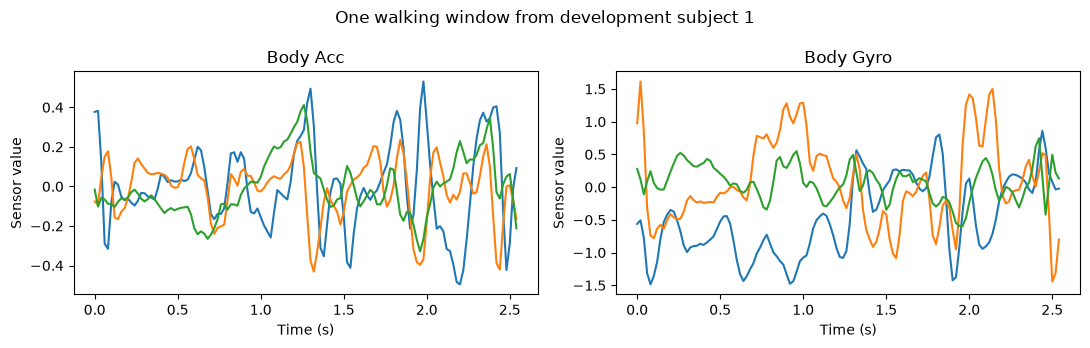

In [2]:
index = np.flatnonzero((subjects == 1) & (labels == 1))[0]
time = np.arange(128) / 50
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
for axis, sensor in zip(axes, ("body_acc", "body_gyro")):
    axis.plot(time, train[sensor][index])
    axis.set_title(sensor.replace("_", " ").title())
    axis.set_xlabel("Time (s)")
    axis.set_ylabel("Sensor value")
fig.suptitle("One walking window from development subject 1")
fig.tight_layout()

## Delay embedding

Chosen lag: 15


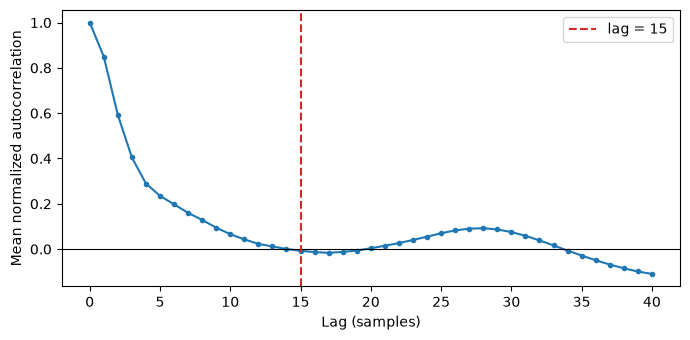

In [3]:
autocorrelation = mean_autocorrelation(train["body_acc"], max_lag=40)
chosen_lag = int(np.flatnonzero(autocorrelation[1:] <= 0)[0] + 1)
plt.figure(figsize=(7, 3.5))
plt.plot(np.arange(41), autocorrelation, marker="o", markersize=3)
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(chosen_lag, color="tab:red", linestyle="--", label=f"lag = {chosen_lag}")
plt.xlabel("Lag (samples)")
plt.ylabel("Mean normalized autocorrelation")
plt.legend()
plt.tight_layout()
print("Chosen lag:", chosen_lag)

### Normalize the point cloud

Cloud shape: (98, 9) raw RMS radius: 0.5179


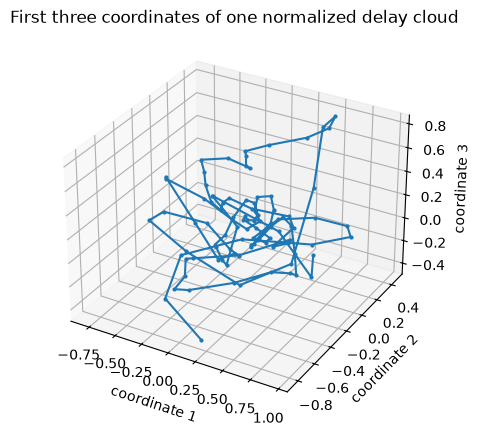

In [4]:
raw_cloud = delay_cloud(train["body_acc"][index], m=3, lag=15)
cloud, radius = normalize_cloud(raw_cloud)
fig = plt.figure(figsize=(6, 5))
axis = fig.add_subplot(projection="3d")
axis.plot(cloud[:, 0], cloud[:, 1], cloud[:, 2], marker="o", markersize=2)
axis.set_title("First three coordinates of one normalized delay cloud")
axis.set_xlabel("coordinate 1")
axis.set_ylabel("coordinate 2")
axis.set_zlabel("coordinate 3")
print("Cloud shape:", cloud.shape, "raw RMS radius:", round(radius, 4))

### Combine accelerometer and gyroscope

In [5]:
equal_joint_cloud, joint_radii = joint_delay_cloud(
    train["body_acc"][index],
    train["body_gyro"][index],
    acceleration_weight=0.5,
    m=3,
    lag=15,
)
print("Separate acceleration cloud:", cloud.shape)
print("Joint acceleration-gyroscope cloud:", equal_joint_cloud.shape)
print("Acceleration and gyroscope radii:", np.round(joint_radii, 4))

acceleration_cloud, _ = normalize_cloud(
    delay_cloud(train["body_acc"][index], m=3, lag=15)
)
gyroscope_cloud, _ = normalize_cloud(
    delay_cloud(train["body_gyro"][index], m=3, lag=15)
)
acceleration_distance = np.linalg.norm(acceleration_cloud[0] - acceleration_cloud[1])
gyroscope_distance = np.linalg.norm(gyroscope_cloud[0] - gyroscope_cloud[1])
formula_distance = np.sqrt(
    0.5 * acceleration_distance**2 + 0.5 * gyroscope_distance**2
)
computed_distance = np.linalg.norm(equal_joint_cloud[0] - equal_joint_cloud[1])
print("Example distance from formula:", round(formula_distance, 8))
print("Example distance in joined cloud:", round(computed_distance, 8))

Separate acceleration cloud: (98, 9)
Joint acceleration-gyroscope cloud: (98, 18)
Acceleration and gyroscope radii: [0.5179 1.583 ]
Example distance from formula: 0.37187389
Example distance in joined cloud: 0.37187389


## Persistent homology and stable ranks

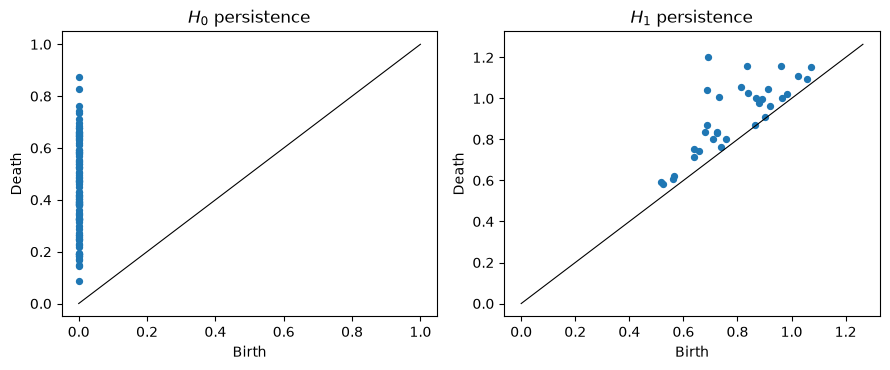

In [6]:
diagram = ripser(cloud, maxdim=1, coeff=47)["dgms"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for dimension, axis in enumerate(axes):
    finite = diagram[dimension][np.isfinite(diagram[dimension][:, 1])]
    limit = max(1.0, finite.max() * 1.05) if len(finite) else 1.0
    axis.scatter(finite[:, 0], finite[:, 1], s=18)
    axis.plot((0, limit), (0, limit), color="black", linewidth=0.8)
    axis.set(title=f"$H_{dimension}$ persistence", xlabel="Birth", ylabel="Death")
fig.tight_layout()

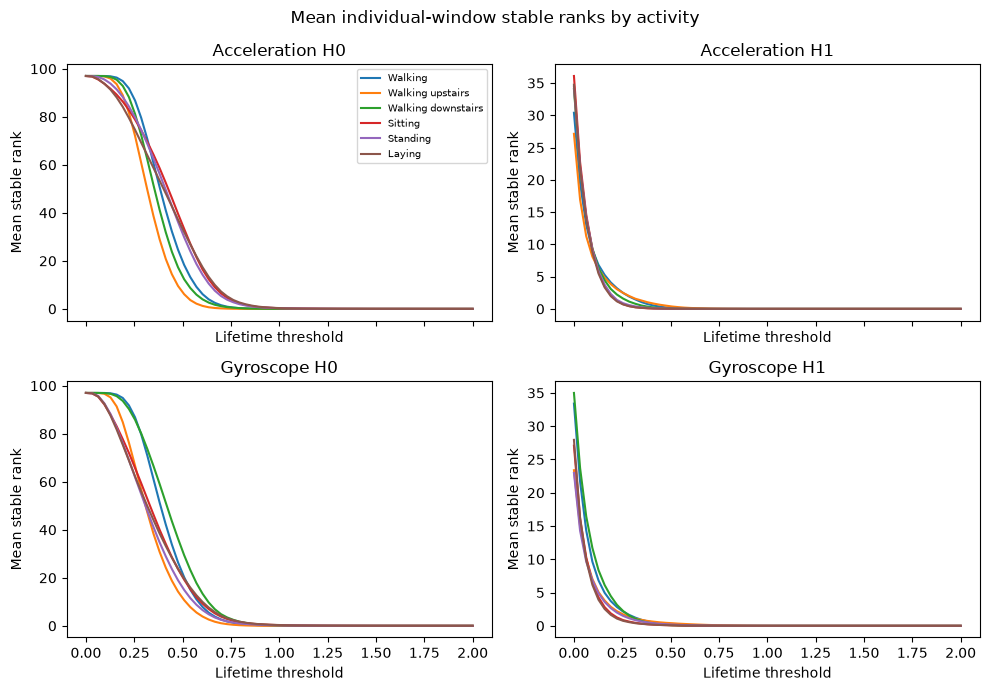

In [7]:
ranks = delay["train_ranks"]
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)
titles = ("Acceleration H0", "Acceleration H1", "Gyroscope H0", "Gyroscope H1")
for block, (axis, title) in enumerate(zip(axes.flat, titles)):
    start = block * len(GRID)
    for activity, name in ACTIVITIES.items():
        axis.plot(GRID, ranks[labels == activity, start:start + len(GRID)].mean(axis=0),
                  label=name)
    axis.set_title(title)
    axis.set_ylabel("Mean stable rank")
    axis.set_xlabel("Lifetime threshold")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Mean individual-window stable ranks by activity")
fig.tight_layout()

### Joint stable ranks

Joint stable-rank vector shape: (128,)


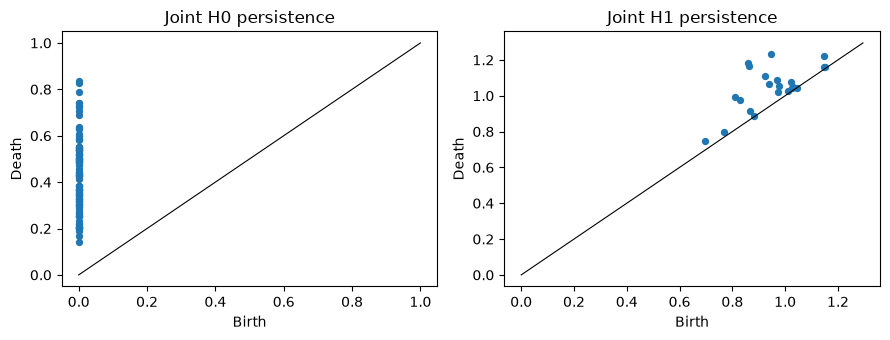

In [8]:
joint_diagrams = ripser(equal_joint_cloud, maxdim=1, coeff=47)["dgms"]
equal_joint_vector = np.concatenate([
    stable_rank(joint_diagrams[0]),
    stable_rank(joint_diagrams[1]),
])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for dimension, axis in enumerate(axes):
    finite = joint_diagrams[dimension][
        np.isfinite(joint_diagrams[dimension][:, 1])
    ]
    limit = max(1.0, finite.max() * 1.05) if len(finite) else 1.0
    axis.scatter(finite[:, 0], finite[:, 1], s=18)
    axis.plot((0, limit), (0, limit), color="black", linewidth=0.8)
    axis.set(title=f"Joint H{dimension} persistence", xlabel="Birth", ylabel="Death")
fig.tight_layout()
print("Joint stable-rank vector shape:", equal_joint_vector.shape)

### Hybrid representation

In [9]:
equal_hybrid_vector = np.concatenate((
    delay["train_ranks"][index],
    equal_joint_vector,
))
print("Separate-sensor vector shape:", delay["train_ranks"][index].shape)
print("Equal-weight joint vector shape:", equal_joint_vector.shape)
print("Equal-weight hybrid vector shape:", equal_hybrid_vector.shape)

Separate-sensor vector shape: (256,)
Equal-weight joint vector shape: (128,)
Equal-weight hybrid vector shape: (384,)


### Add physical scale

In [10]:
equal_hybrid_scale_vector = np.concatenate((
    equal_hybrid_vector,
    delay["train_scales"][index],
))
print("Hybrid shape coordinates:", equal_hybrid_vector.shape)
print("Appended sensor radii:", np.round(delay["train_scales"][index], 4))
print("Hybrid plus scale vector shape:", equal_hybrid_scale_vector.shape)

Hybrid shape coordinates: (384,)
Appended sensor radii: [0.5179 1.583 ]
Hybrid plus scale vector shape: (386,)


## Evaluation

### Joint weight search

Selected acceleration weight: 1.0
Selected gyroscope weight: 0.0


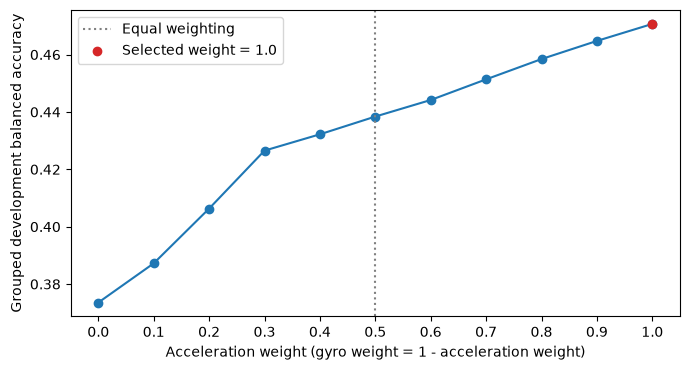

In [11]:
weight_analysis = results["joint_sensor_weight_search"]
weight_grid = weight_analysis["grid"]
weights = np.asarray([row["acceleration_weight"] for row in weight_grid])
weight_scores = np.asarray([row["balanced_accuracy"] for row in weight_grid])
selected_weight = weight_analysis["selected_acceleration_weight"]

plt.figure(figsize=(7, 3.8))
plt.plot(weights, weight_scores, marker="o")
plt.axvline(0.5, color="gray", linestyle=":", label="Equal weighting")
plt.scatter(
    [selected_weight],
    [weight_scores[np.flatnonzero(np.isclose(weights, selected_weight))[0]]],
    color="tab:red",
    zorder=3,
    label=f"Selected weight = {selected_weight:.1f}",
)
plt.xlabel("Acceleration weight (gyro weight = 1 - acceleration weight)")
plt.ylabel("Grouped development balanced accuracy")
plt.xticks(weights)
plt.legend()
plt.tight_layout()
print("Selected acceleration weight:", selected_weight)
print("Selected gyroscope weight:", weight_analysis["selected_gyroscope_weight"])

### Hybrid weight search

Selected hybrid acceleration weight: 0.4
Selected hybrid gyro weight: 0.6


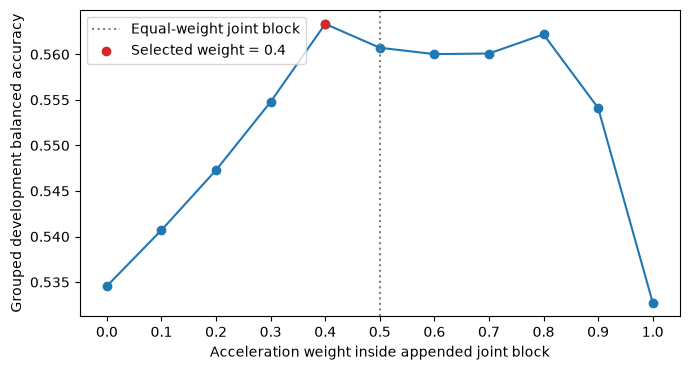

In [12]:
hybrid_analysis = results["hybrid_sensor_weight_search"]
hybrid_grid = hybrid_analysis["grid"]
hybrid_weights = np.asarray([row["acceleration_weight"] for row in hybrid_grid])
hybrid_scores = np.asarray([row["balanced_accuracy"] for row in hybrid_grid])
selected_hybrid_weight = hybrid_analysis["selected_acceleration_weight"]

plt.figure(figsize=(7, 3.8))
plt.plot(hybrid_weights, hybrid_scores, marker="o")
plt.axvline(0.5, color="gray", linestyle=":", label="Equal-weight joint block")
selected_position = np.flatnonzero(
    np.isclose(hybrid_weights, selected_hybrid_weight)
)[0]
plt.scatter(
    [selected_hybrid_weight], [hybrid_scores[selected_position]],
    color="tab:red", zorder=3,
    label=f"Selected weight = {selected_hybrid_weight:.1f}",
)
plt.xlabel("Acceleration weight inside appended joint block")
plt.ylabel("Grouped development balanced accuracy")
plt.xticks(hybrid_weights)
plt.legend()
plt.tight_layout()
print("Selected hybrid acceleration weight:", selected_hybrid_weight)
print("Selected hybrid gyro weight:", hybrid_analysis["selected_gyroscope_weight"])

### Stable ranks at the selected joint weight

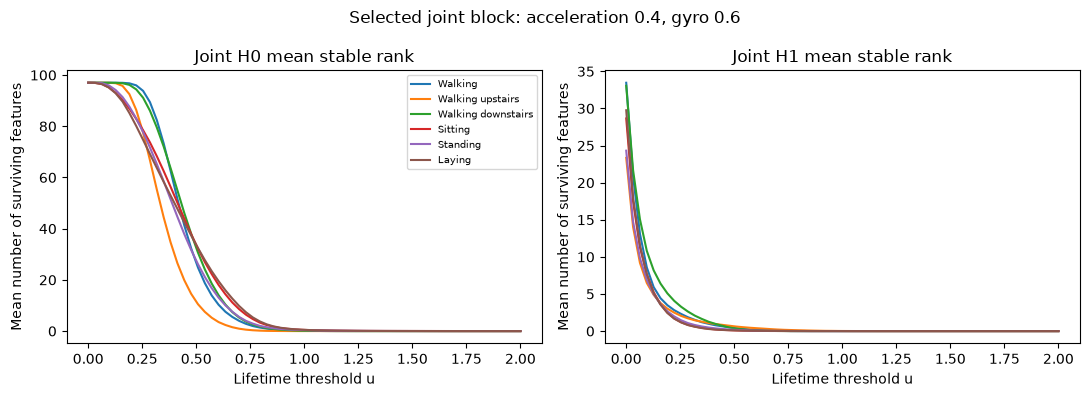

In [13]:
selected_joint_position = np.flatnonzero(
    np.isclose(joint_train["weights"], selected_hybrid_weight)
)[0]
selected_joint_ranks = joint_train["train_ranks"][selected_joint_position]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for dimension, axis in enumerate(axes):
    block = selected_joint_ranks[
        :, dimension * len(GRID):(dimension + 1) * len(GRID)
    ]
    for activity, name in ACTIVITIES.items():
        axis.plot(GRID, block[labels == activity].mean(axis=0), label=name)
    axis.set_title(f"Joint H{dimension} mean stable rank")
    axis.set_xlabel("Lifetime threshold u")
    axis.set_ylabel("Mean number of surviving features")
axes[0].legend(fontsize=7)
fig.suptitle(
    f"Selected joint block: acceleration {selected_hybrid_weight:.1f}, "
    f"gyro {1 - selected_hybrid_weight:.1f}"
)
fig.tight_layout()

## Classification results

Instantaneous TDA         BA=0.558  F1=0.553
Delay TDA                 BA=0.580  F1=0.576
Joint-sensor TDA          BA=0.484  F1=0.474
Hybrid TDA                BA=0.611  F1=0.608
Hybrid TDA + scale        BA=0.663  F1=0.664
Shuffled-delay TDA        BA=0.499  F1=0.483
Delay TDA + scale         BA=0.639  F1=0.640
UCI 561 baseline          BA=0.954  F1=0.955


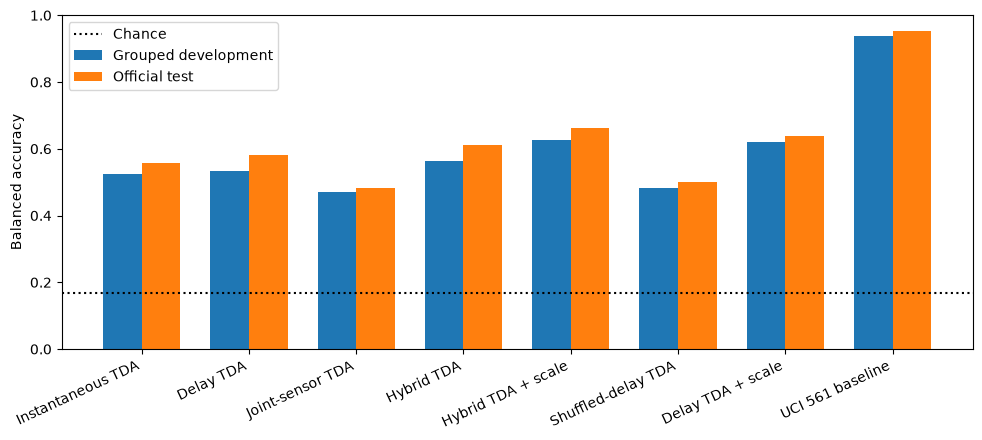

In [14]:
names = list(results["models"])
development = [results["models"][name]["development"]["balanced_accuracy"] for name in names]
official = [results["models"][name]["official_test"]["balanced_accuracy"] for name in names]
x = np.arange(len(names))
plt.figure(figsize=(10, 4.5))
plt.bar(x - 0.18, development, 0.36, label="Grouped development")
plt.bar(x + 0.18, official, 0.36, label="Official test")
plt.axhline(1 / 6, color="black", linestyle=":", label="Chance")
plt.xticks(x, names, rotation=25, ha="right")
plt.ylabel("Balanced accuracy")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
for name in names:
    score = results["models"][name]["official_test"]
    print(f"{name:25s} BA={score['balanced_accuracy']:.3f}  F1={score['macro_f1']:.3f}")